# Titanic Survival Prediction
Predicting passenger survival with engineered features, a model comparison, tuning, and stacking.
Dataset: Kaggle *Titanic: Machine Learning from Disaster* (`train.csv`, `test.csv`).

In [1]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

from features import add_features, get_xy, NUM_COLS, CAT_COLS

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load data

In [3]:
train = pd.read_csv("../data/train.csv")
print(train.shape)
train.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Quick EDA

In [4]:
missing = (train.isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing[missing > 0])
print("\nSurvival rate:", train["Survived"].mean().round(3))

Cabin       77.1
Age         19.9
Embarked     0.2
dtype: float64

Survival rate: 0.384


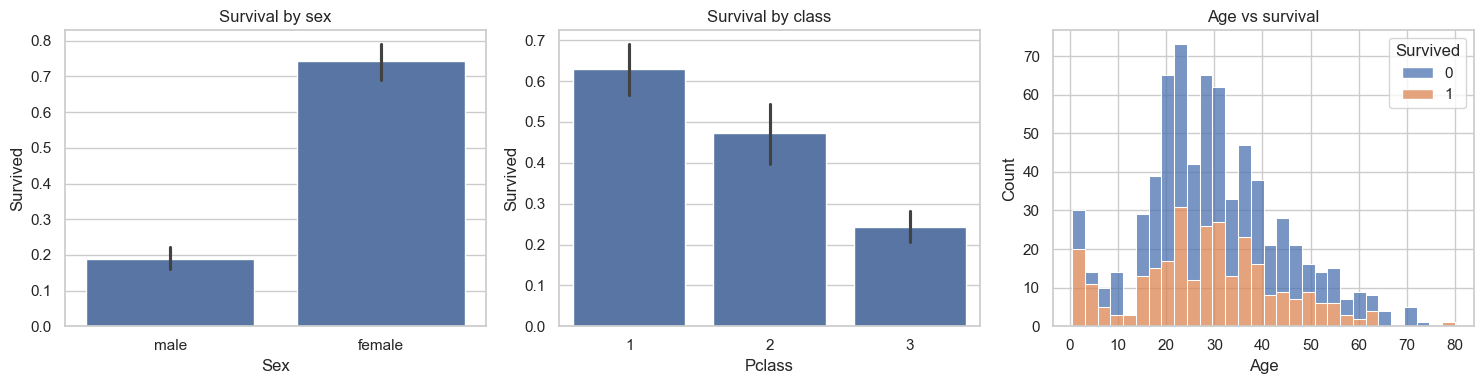

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=train, x="Sex", y="Survived", ax=ax[0])
sns.barplot(data=train, x="Pclass", y="Survived", ax=ax[1])
sns.histplot(data=train, x="Age", hue="Survived", bins=30, multiple="stack", ax=ax[2])
ax[0].set_title("Survival by sex"); ax[1].set_title("Survival by class"); ax[2].set_title("Age vs survival")
plt.tight_layout(); plt.show()

## 3. Feature engineering
Instead of dropping `Cabin`, I keep what it offers (`HasCabin`, `Deck`). New features:
`Title` (from `Name`), `FamilySize`, `IsAlone`, `FarePerPerson`.

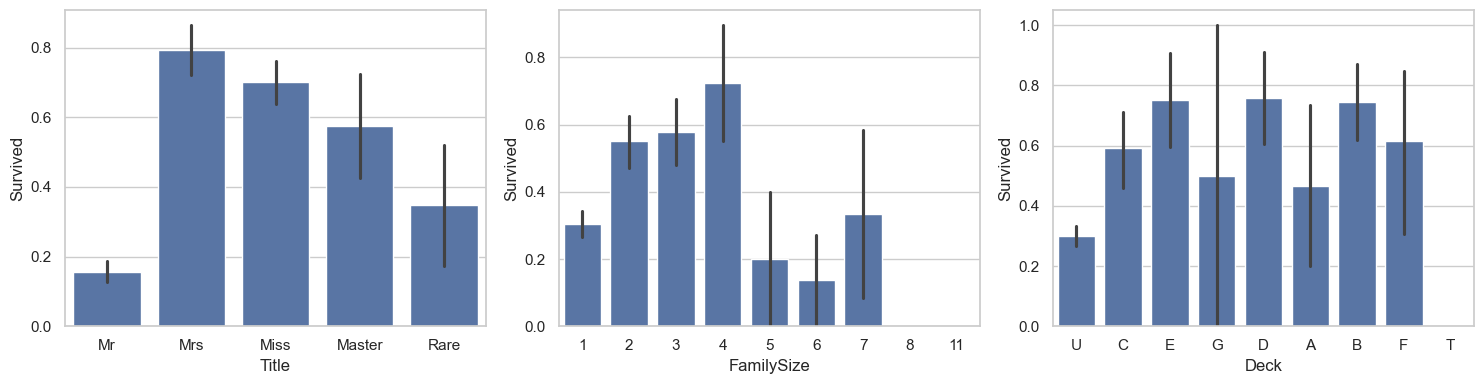

In [6]:
eng = add_features(train)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=eng, x="Title", y="Survived", ax=ax[0])
sns.barplot(data=eng, x="FamilySize", y="Survived", ax=ax[1])
sns.barplot(data=eng, x="Deck", y="Survived", ax=ax[2])
plt.tight_layout(); plt.show()

In [7]:
X, y = get_xy(train)

numeric_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
categorical_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUM_COLS),
    ("cat", categorical_pipe, CAT_COLS),
])
X.shape

(891, 13)

## 4. Model comparison (5-fold stratified CV)

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    s = cross_validate(pipe, X, y, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    rows.append({"Model": name,
                 "Accuracy": s["test_accuracy"].mean(),
                 "F1": s["test_f1"].mean(),
                 "ROC-AUC": s["test_roc_auc"].mean()})
results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).round(4).reset_index(drop=True)
results

,Model,Accuracy,F1,ROC-AUC
0,SVM,0.8294,0.7671,0.8573
1,Logistic Regression,0.8283,0.7727,0.8719
2,HistGradientBoosting,0.8226,0.7658,0.8811
3,XGBoost,0.8181,0.7625,0.8744
4,Random Forest,0.8159,0.7571,0.8727


## 5. Tune the best model

In [9]:
param_space = {
    "Logistic Regression": {"model__C": np.logspace(-2, 2, 20)},
    "Random Forest": {"model__n_estimators": [200, 300, 500], "model__max_depth": [4, 6, 8, 12, None],
                      "model__min_samples_leaf": [1, 2, 4]},
    "SVM": {"model__C": np.logspace(-1, 2, 10), "model__gamma": ["scale", 0.01, 0.05, 0.1]},
    "HistGradientBoosting": {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [3, 4, 6, None],
                             "model__max_iter": [100, 200, 300]},
    "XGBoost": {"model__n_estimators": [100, 200, 400], "model__max_depth": [2, 3, 4, 5],
                "model__learning_rate": [0.02, 0.05, 0.1], "model__subsample": [0.7, 0.85, 1.0]},
}
best_name = results.loc[0, "Model"]
print("Tuning:", best_name)

search = RandomizedSearchCV(
    Pipeline([("prep", preprocess), ("model", models[best_name])]),
    param_space[best_name], n_iter=25, scoring="accuracy", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1,
)
search.fit(X, y)
print("Best CV accuracy:", round(search.best_score_, 4))
search.best_params_

Tuning: SVM
Best CV accuracy: 0.835


{'model__gamma': 'scale', 'model__C': np.float64(2.1544346900318834)}

## 6. Stacking the top 3 models

In [10]:
top3 = results["Model"].head(3).tolist()
stack = Pipeline([
    ("prep", preprocess),
    ("model", StackingClassifier(
        estimators=[(n, models[n]) for n in top3],
        final_estimator=LogisticRegression(max_iter=1000), cv=5)),
])
s = cross_validate(stack, X, y, cv=cv, scoring=["accuracy", "f1"])
print("Stack of", top3)
print("Stack CV accuracy:", s["test_accuracy"].mean().round(4), "| F1:", s["test_f1"].mean().round(4))
print("Tuned single model:", round(search.best_score_, 4))

Stack of ['SVM', 'Logistic Regression', 'HistGradientBoosting']
Stack CV accuracy: 0.8474 | F1: 0.7898
Tuned single model: 0.835


## 7. Hold-out evaluation

              precision    recall  f1-score   support

        Died       0.82      0.90      0.86       110
    Survived       0.81      0.70      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



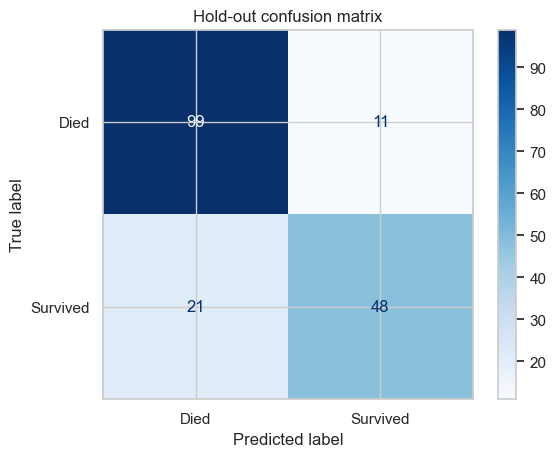

In [11]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
final_model = search.best_estimator_.fit(X_tr, y_tr)
pred = final_model.predict(X_val)
print(classification_report(y_val, pred, target_names=["Died", "Survived"]))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred), display_labels=["Died", "Survived"]).plot(cmap="Blues")
plt.title("Hold-out confusion matrix"); plt.show()

## 8. What drives the predictions? (permutation importance)

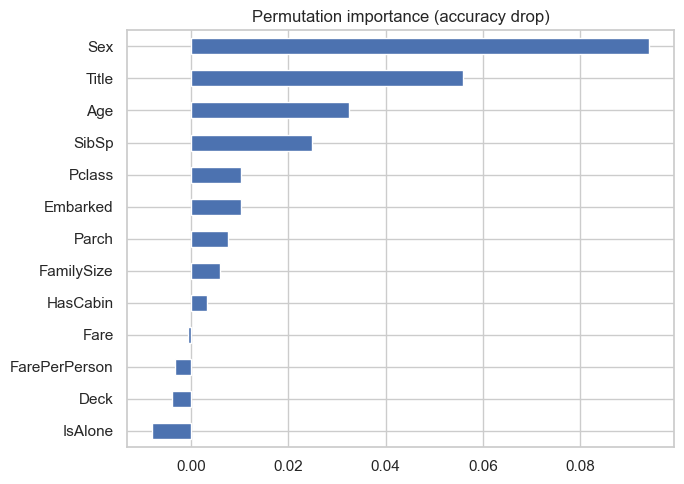

In [12]:
pi = permutation_importance(final_model, X_val, y_val, n_repeats=20, random_state=RANDOM_STATE, scoring="accuracy")
imp = pd.Series(pi.importances_mean, index=X_val.columns).sort_values()
imp.plot.barh(figsize=(7, 5), title="Permutation importance (accuracy drop)")
plt.tight_layout(); plt.show()

## 9. Final fit and Kaggle submission

In [13]:
import os
final_model = search.best_estimator_.fit(X, y)
test_path = "../data/test.csv"
if os.path.exists(test_path):
    test = pd.read_csv(test_path)
    sub = pd.DataFrame({"PassengerId": test["PassengerId"],
                        "Survived": final_model.predict(get_xy(test, with_target=False))})
    os.makedirs("../submissions", exist_ok=True)
    sub.to_csv("../submissions/submission.csv", index=False)
    print("Saved submissions/submission.csv", sub.shape)
else:
    print("Put Kaggle's test.csv in data/ to generate a submission.")

Saved submissions/submission.csv (418, 2)


## 10. Conclusions
- Sex, passenger class and title were the strongest signals.
- Engineered features (title, family size, deck) added signal beyond the raw columns.
- *Fill in: best CV accuracy, Kaggle leaderboard score, and what you would try next.*
- - Stacking SVM, Logistic Regression and HistGradientBoosting scored best in CV (0.847 accuracy), ahead of the tuned SVM (0.835).
- The tuned SVM reached 0.82 accuracy on the hold-out set, but recall on survivors was only 0.70, so it misses more survivors than victims.
- Next: try more feature interactions (e.g. Title x Pclass) and tune the stack's meta-learner.